# One frame through the field pipeline: frame 42886 (2-fish ground truth)

EOD row 17138 of `data/2_fish_silent` falls in video frame 42886. Fish 1 (larger) is the emitter and fish 0 is silent; the
assignment gave this EOD to fish 0. This notebook runs every step of the model exactly as the assignment did
(`eod_assign.candidate_field` → `pair_voltages` → `compare_patterns`, same parameters as `EOD_assignment_ground_truth.ipynb`),
shows what each step produces, and checks at the end that it reproduces the cached result.

1. the recorded EOD and the pattern the assignment uses
2. masks of the frame and electrodes
3. midline and head of each fish
4. masks on the N × N tank grid
5. point currents of the emitting fish
6. conductivity: water, the other fish's body and skin
7. solving for the potential, and the electric field in the tank
8. sampling the potential at the electrodes
9. comparison with the recording and assignment

All maps are drawn in video orientation (x = pixel column, y = pixel row, as in the camera image).

In [1]:
import pickle, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgba, SymLogNorm, LogNorm
import mask_metrics as mm                         # ZEUS crop unpacking (sets the Agg backend...)
%matplotlib inline
from compute_electric_field import (mask_to_grid, multipole_sources, build_multipole_b, occupancy_field, theta_outer, gammas,
                                    build_A_shell, solve_potential, unflatten_to_grid, sample_phi_point)
from midline_methods import fish_midline_with_head
from eod_assign import (load_electrode_pairs, eod_sample_count, recorded_pair_traces, peak_pattern, candidate_field,
                        pair_voltages, normalize_peak, compare_patterns)

FRAME = 42886                                 # the frame analysed here (its assessed EOD is looked up below)
DATA = 'data/2_fish_silent'
EOD_CSV = f'{DATA}/Data_1fish_2024-02-13T14_33_21.csv'
TRACK_PKL = f'{DATA}/elephantnose_20240213T143321_tracking_final.pkl'
VIDEO = f'{DATA}/video2024-02-13T14_33_21.avi'
ELECTRODES_CSV = 'data/electrodes_signed_px_coord_2024-02-13.csv'
OUT = 'results/eod_ground_truth'

FISH, EMITTER = (0, 1), 1
FISH_COLOR = {0: '#2E8B57', 1: '#D45087'}
FS = 50000.0                                    # electrode sampling rate (Hz)
# field model: the parameters of the assignment run
N = 150                                         # tank grid resolution (N x N)
n_poles = 100                                   # n_poles + 1 point currents along each midline, tail -> head
delta_h = 0.5                                   # skin thickness, in grid-cell units
MAT = dict(sigma_water=1.0, eps_water=0.0, sigma_interior=200.0, eps_interior=0.0, sigma_skin=0.05, eps_skin=2.7e-6)
OMEGA = 0.0                                     # resistive solve

df_eod = pd.read_csv(EOD_CSV)
assigned = pd.read_csv(f'{OUT}/eod_assignments_my_pipeline.csv', index_col='row')
EOD_ROW = int(assigned.index[assigned.frame == FRAME][0])                 # the assessed EOD of this frame
row = df_eod.loc[EOD_ROW]
assert int(row.Frame) == FRAME
n_samp = eod_sample_count(df_eod)
with open(TRACK_PKL, 'rb') as f:
    trk = pickle.load(f)
P = trk['shape'][0]
pairs = load_electrode_pairs(ELECTRODES_CSV, P)          # [(pair id, + point, - point)], tank coords (row, col) / (P - 1)
pair_ids = [pid for pid, _, _ in pairs]
h = 1.0 / (N - 1)                                        # grid spacing in tank units
print(f"EOD row {EOD_ROW}: frame {FRAME}, t = {row.Time:.2f} s | video {P} x {P} px | grid {N} x {N}, one cell = "
      f"{(P - 1) / (N - 1):.2f} px")
print("good frame (mask QC + SLEAP):", FRAME in set(pd.read_csv(f'{OUT}/common_good_frames.csv').frame))

def px(p):
    '''Tank point(s) (row, col) in [0, 1] -> plotting coordinates (x = col px, y = row px).'''
    p = np.asarray(p) * (P - 1)
    return p[..., 1], p[..., 0]

def draw_electrodes(ax, labels=True, ms=11):
    '''Electrodes at their positions, + red, - blue, labelled with the pair number.'''
    for pid, pp, pm in pairs:
        for pt, sgn, col, mk in ((pp, '+', '#E74C3C', '+'), (pm, '−', '#2C6FBB', '_')):
            x, y = px(pt)
            ax.plot(x, y, mk, color=col, ms=ms, mew=2.5)
            if labels:
                off = np.array([P / 2 - x, P / 2 - y]); off = 34 * off / np.linalg.norm(off)
                ax.text(x + off[0], y + off[1], f'{pid}{sgn}', color=col, fontsize=8, fontweight='bold', ha='center',
                        va='center', bbox=dict(boxstyle='round,pad=0.1', fc='white', ec='none', alpha=0.85))

def tank_axes(ax, title):
    ax.set(xlim=(-10, P + 10), ylim=(P + 10, -10), aspect='equal', xticks=[], yticks=[], title=title)

EXTENT = [-0.5 * (P - 1) / (N - 1), (P - 1) * (1 + 0.5 / (N - 1)), (P - 1) * (1 + 0.5 / (N - 1)), -0.5 * (P - 1) / (N - 1)]

EOD row 17138: frame 42886, t = 857.71 s | video 912 x 912 px | grid 150 x 150, one cell = 6.11 px
good frame (mask QC + SLEAP): True


## 1. The recorded EOD

`recorded_pair_traces`: the 25 samples (0.5 ms at 50 kHz) of each electrode pair around the EOD, each pair demeaned.
`peak_pattern`: the sample where |V| peaks over all pairs; the 10 voltages at that sample are the recorded pattern $r$ that the
assignment compares with the model.

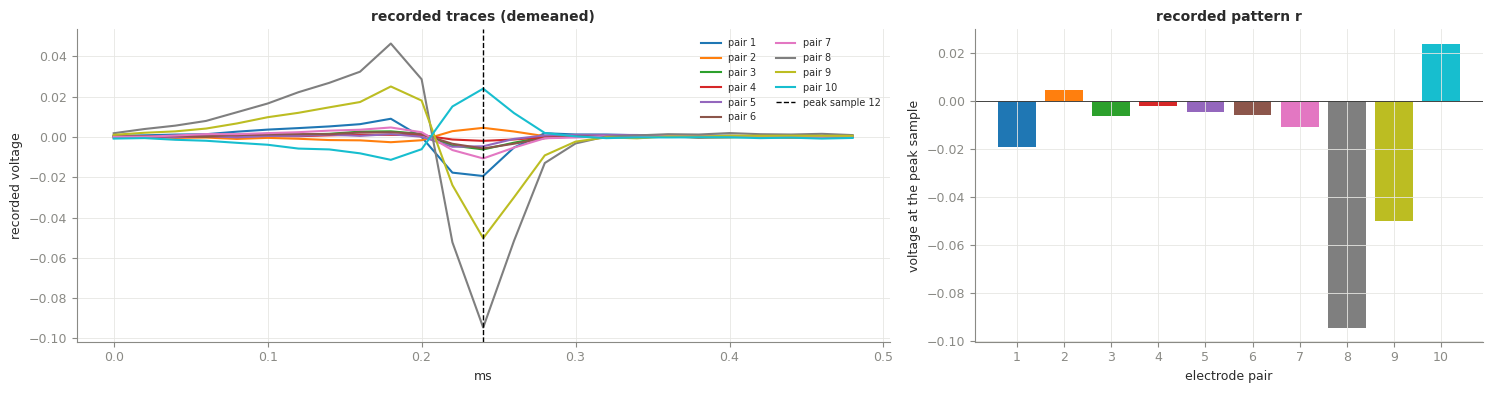

pair,1,2,3,4,5,6,7,8,9,10
r,-0.0194,0.0045,-0.0062,-0.0020,-0.0047,-0.0057,-0.0107,-0.0946,-0.0502,0.0239
r / max|r|,-0.2053,0.0475,-0.0657,-0.0208,-0.0493,-0.0606,-0.1131,-1.0000,-0.5311,0.2531


In [2]:
V = recorded_pair_traces(row, pair_ids, n_samp)
r, t_star = peak_pattern(V)
t_ms = np.arange(n_samp) / FS * 1e3

fig, ax = plt.subplots(1, 2, figsize=(15, 4), gridspec_kw=dict(width_ratios=[1.6, 1]))
cols = plt.cm.tab10(np.arange(len(pair_ids)))
for k, pid in enumerate(pair_ids):
    ax[0].plot(t_ms, V[k], color=cols[k], lw=1.5, label=f'pair {pid}')
ax[0].axvline(t_ms[t_star], color='k', ls='--', lw=1, label=f'peak sample {t_star}')
ax[0].set(xlabel='ms', ylabel='recorded voltage', title='recorded traces (demeaned)'); ax[0].legend(fontsize=7, ncol=2)
ax[1].bar(pair_ids, r, color=cols); ax[1].axhline(0, color='k', lw=0.5)
ax[1].set(xticks=pair_ids, xlabel='electrode pair', ylabel='voltage at the peak sample', title='recorded pattern r')
plt.tight_layout(); plt.show()
display(pd.DataFrame({'r': r, 'r / max|r|': normalize_peak(r)}, index=pd.Index(pair_ids, name='pair')).T.round(4))

## 2. Masks and electrodes

The ZEUS masks of this frame (label 0 = fish 0, label 1 = fish 1), full-frame (P × P) boolean arrays.

,label,"box (y0, y1, x0, x1)",area (px)
0,1,"(641, 859, 26, 146)",4454
1,0,"(148, 300, 776, 846)",2530


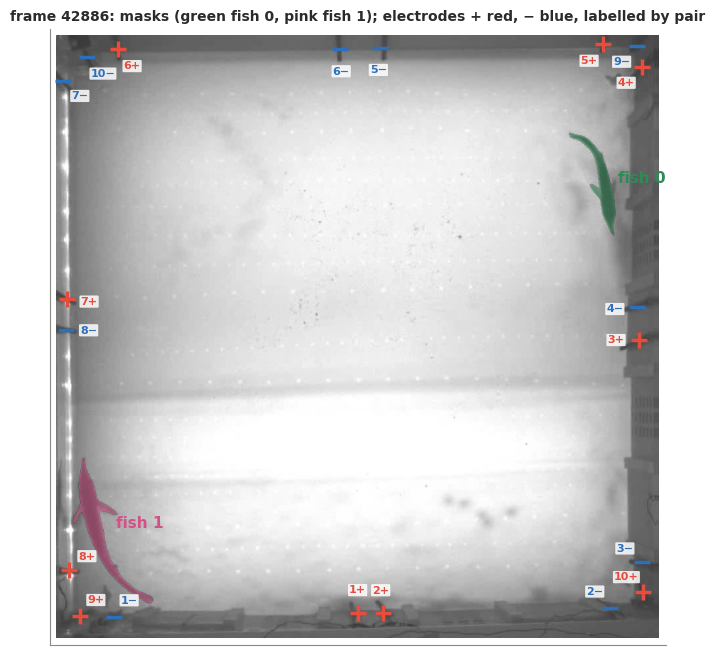

In [3]:
def video_frame(k):
    out = subprocess.run(['ffmpeg', '-v', 'error', '-ss', f'{k / trk["fps"]:.4f}', '-i', VIDEO, '-frames:v', '1', '-f', 'rawvideo',
                          '-pix_fmt', 'gray', '-'], capture_output=True, check=True).stdout
    return np.frombuffer(out, np.uint8).reshape(P, P)

fr = trk['frames'][FRAME]
fm = np.zeros((len(FISH), P, P), bool)
for l, packed, (y0, y1, x0, x1) in zip(fr['labels'], fr['masks'], fr['boxes']):
    if l in FISH: fm[l, y0:y1, x0:x1] = mm.unpack_crop(packed, (y0, y1, x0, x1))
display(pd.DataFrame({'label': fr['labels'], 'box (y0, y1, x0, x1)': fr['boxes'], 'area (px)': fr['areas']}))

img = video_frame(FRAME)
fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(img, cmap='gray')
over = np.zeros((P, P, 4))
for f in FISH: over[fm[f]] = to_rgba(FISH_COLOR[f], 0.5)
ax.imshow(over); draw_electrodes(ax)
for f in FISH:
    cy, cx = np.argwhere(fm[f]).mean(0); ax.text(cx + 25, cy, f'fish {f}', color=FISH_COLOR[f], fontsize=11, fontweight='bold')
tank_axes(ax, f'frame {FRAME}: masks (green fish 0, pink fish 1); electrodes + red, − blue, labelled by pair')
plt.show()

## 3. Midline and head of each fish

`fish_midline_with_head(mask, n_ctrl = n_poles + 1)`:
- **tips**: the two pixels furthest apart *through the body* (shortest paths inside the mask);
- **head (area rule)**: the end whose first third of the body (by distance through the body) holds more pixels, since the head end is
  wider than the tail;
- **midline**: smoothing spline through the centroids of slices across the body, resampled to `n_poles + 1` points evenly spaced by
  arc length, oriented tail → head, in tank units.

,fish 0,fish 1
"tip a (row, col)","[149, 776]","[856, 145]"
"tip b (row, col)","[299, 843]","[641, 41]"
pixels in first third from a,553,831
pixels in first third from b,881,2016
head,b,b
midline points,101,101
length (px),175.106397,252.230976


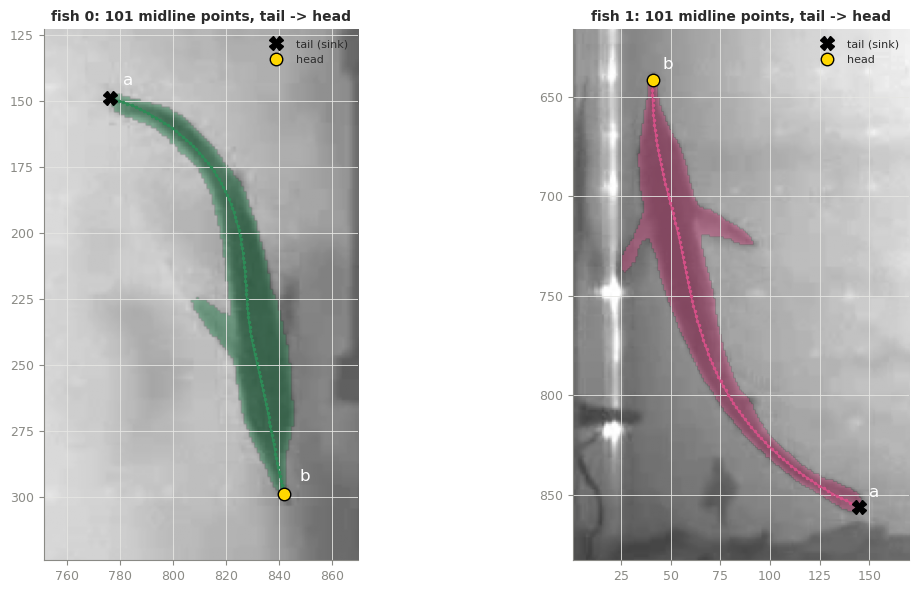

In [4]:
body = {f: fish_midline_with_head(fm[f], n_ctrl=n_poles + 1) for f in FISH}
mids = {f: body[f]['midline'] for f in FISH}
display(pd.DataFrame({f'fish {f}': {'tip a (row, col)': body[f]['tip_a'].astype(int), 'tip b (row, col)': body[f]['tip_b'].astype(int),
                                    'pixels in first third from a': body[f]['area_a'], 'pixels in first third from b': body[f]['area_b'],
                                    'head': 'a' if body[f]['head_is_a'] else 'b',
                                    'midline points': len(mids[f]),
                                    'length (px)': np.linalg.norm(np.diff(mids[f], axis=0), axis=1).sum() * (P - 1)} for f in FISH}))

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
for a, f in zip(ax, FISH):
    pix = np.argwhere(fm[f]); (r0, c0), (r1, c1) = pix.min(0) - 25, pix.max(0) + 25
    a.imshow(img, cmap='gray'); a.imshow(np.where(fm[f][..., None], np.array(to_rgba(FISH_COLOR[f], 0.45)), 0))
    x, y = px(mids[f]); a.plot(x, y, '.-', color=FISH_COLOR[f], ms=3, lw=1)
    a.plot(x[0], y[0], 'X', color='k', ms=10, label='tail (sink)'); a.plot(x[-1], y[-1], 'o', color='gold', mec='k', ms=9, label='head')
    for t, lab in ((body[f]['tip_a'], 'a'), (body[f]['tip_b'], 'b')): a.text(t[1] + 5, t[0] - 5, lab, color='w', fontsize=12)
    a.set(xlim=(c0, c1), ylim=(r1, r0), title=f'fish {f}: {len(mids[f])} midline points, tail -> head'); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 4. The tank grid

The solve runs on an N × N grid over the tank: grid node (i, j) sits at tank point (i h, j h), h = 1/(N − 1), i.e. pixel row
i (P − 1)/(N − 1), column j (P − 1)/(N − 1). The tank edges are the grid edges (insulating walls). Masks are downsampled to the grid with
`mask_to_grid` (nearest neighbour), and as a smooth occupancy in [0, 1] with `occupancy_field` (linear interpolation, > 0.5 = inside).

one grid cell = 6.11 px | grid cells inside: fish 0 66 (68 expected from the pixel area), fish 1 120 (119 expected from the pixel area)
width of each fish (px, mask; cells): fish 0 14.4 px = 2.4 cells, fish 1 17.7 px = 2.9 cells


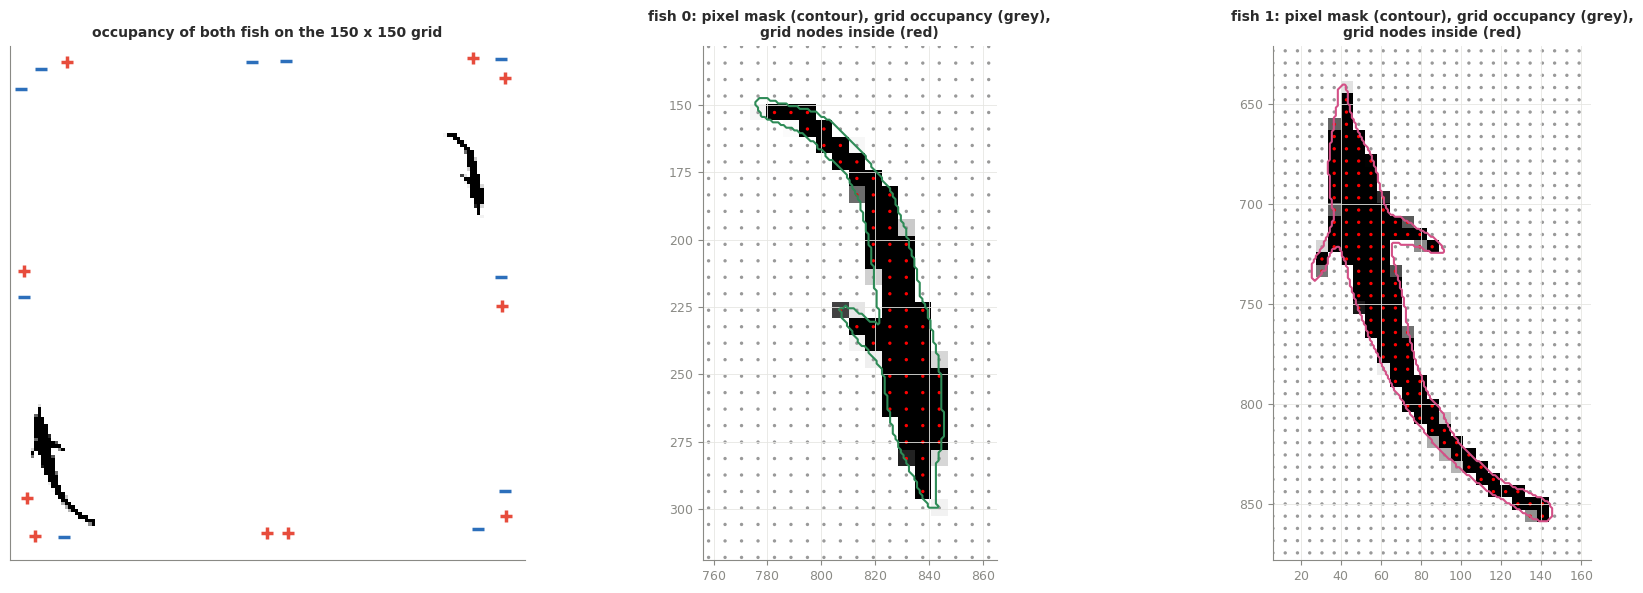

In [5]:
cell_px = (P - 1) / (N - 1)
grid_m = {f: mask_to_grid(fm[f], N) for f in FISH}
occ_all = occupancy_field(fm, N)
print(f"one grid cell = {cell_px:.2f} px | grid cells inside: " +
      ', '.join(f"fish {f} {grid_m[f].sum()} ({fm[f].sum() / cell_px ** 2:.0f} expected from the pixel area)" for f in FISH))
print("width of each fish (px, mask; cells): " + ', '.join(
      f"fish {f} {fm[f].sum() / (np.linalg.norm(np.diff(mids[f], axis=0), axis=1).sum() * (P - 1)):.1f} px = "
      f"{fm[f].sum() / (np.linalg.norm(np.diff(mids[f], axis=0), axis=1).sum() * (P - 1)) / cell_px:.1f} cells" for f in FISH))

fig, ax = plt.subplots(1, 3, figsize=(18, 6))
ax[0].imshow(occ_all, cmap='Greys', extent=EXTENT); draw_electrodes(ax[0], labels=False, ms=8)
tank_axes(ax[0], f'occupancy of both fish on the {N} x {N} grid')
for a, f in zip(ax[1:], FISH):
    pix = np.argwhere(fm[f]); (r0, c0), (r1, c1) = pix.min(0) - 20, pix.max(0) + 20
    a.imshow(occ_all, cmap='Greys', extent=EXTENT)
    a.contour(fm[f], levels=[0.5], colors=[FISH_COLOR[f]], linewidths=1.5)
    ii, jj = np.meshgrid(np.arange(N), np.arange(N), indexing='ij')
    sel = (ii * cell_px > r0) & (ii * cell_px < r1) & (jj * cell_px > c0) & (jj * cell_px < c1)
    a.scatter(jj[sel] * cell_px, ii[sel] * cell_px, s=2, c=np.where(occ_all[sel] > 0.5, 'r', '0.6'))
    a.set(xlim=(c0, c1), ylim=(r1, r0), aspect='equal', title=f'fish {f}: pixel mask (contour), grid occupancy (grey),\n'
          'grid nodes inside (red)')
plt.tight_layout(); plt.show()

## 5. Point currents of the emitting fish

`multipole_sources(midline, I0 = 1)`: the tail point is a sink of −1, each of the other `n_poles` points a source of +1/`n_poles`,
so the currents sum to 0 (unit current, no length scaling). `build_multipole_b` spreads each point current over the 4 grid nodes
around it (bilinear weights) and removes the mean of the grid, which keeps the net injected current at exactly 0 (needed by the
insulating-wall solve).

fish 0: 101 point currents, tail -1.000, others +0.0100 each, sum +1.7e-17 | grid b: min -0.572, max +0.0328, sum -2.8e-17
fish 1: 101 point currents, tail -1.000, others +0.0100 each, sum +1.7e-17 | grid b: min -0.710, max +0.0228, sum -2.8e-17


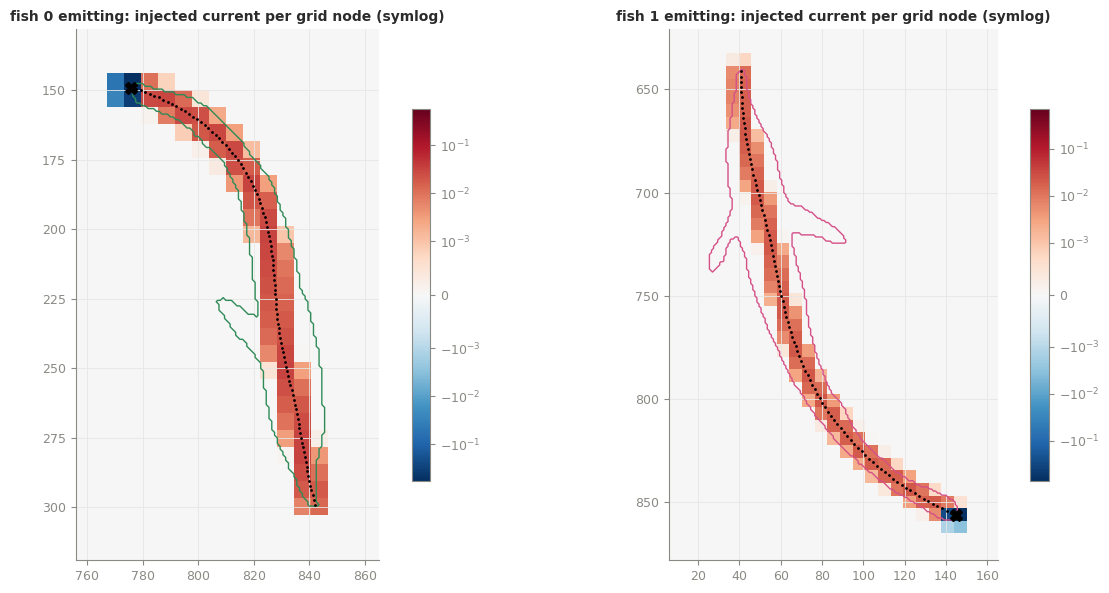

In [6]:
src = {f: multipole_sources(mids[f], I0=1.0) for f in FISH}
b = {f: build_multipole_b(*src[f], h, N) for f in FISH}
for f in FISH:
    pos, cur = src[f]
    print(f"fish {f}: {len(cur)} point currents, tail {cur[0]:+.3f}, others {cur[1]:+.4f} each, sum {cur.sum():+.1e} | "
          f"grid b: min {b[f].min():+.3f}, max {b[f].max():+.4f}, sum {b[f].sum():+.1e}")

fig, ax = plt.subplots(1, 2, figsize=(13, 6))
for a, f in zip(ax, FISH):
    pix = np.argwhere(fm[f]); (r0, c0), (r1, c1) = pix.min(0) - 20, pix.max(0) + 20
    v = np.abs(b[f]).max()
    im = a.imshow(b[f], cmap='RdBu_r', norm=SymLogNorm(1e-3, vmin=-v, vmax=v), extent=EXTENT)
    a.contour(fm[f], levels=[0.5], colors=[FISH_COLOR[f]], linewidths=1)
    x, y = px(src[f][0]); a.plot(x[1:], y[1:], '.', color='k', ms=2); a.plot(x[0], y[0], 'X', color='k', ms=9)
    a.set(xlim=(c0, c1), ylim=(r1, r0), title=f'fish {f} emitting: injected current per grid node (symlog)')
    plt.colorbar(im, ax=a, shrink=0.7)
plt.tight_layout(); plt.show()

## 6. Conductivity

For emitter f, `occupancy_field(masks, N, skip=f)` keeps only the **other** fish: the emitter's own body is transparent (water).
Grid nodes with occupancy > 0.5 get the interior conductivity, the rest water. On every grid edge that crosses the water|body
boundary (`theta_outer`, at the interpolated crossing point), the conductance is water | skin sheet | interior in series, with a skin
of thickness `delta_h` cells (`build_A_shell`). With ω = 0 only the conductivities σ matter.

sigma: water 1.0, skin 0.05 (thickness 0.5 cell = 3.1 px), interior 200.0


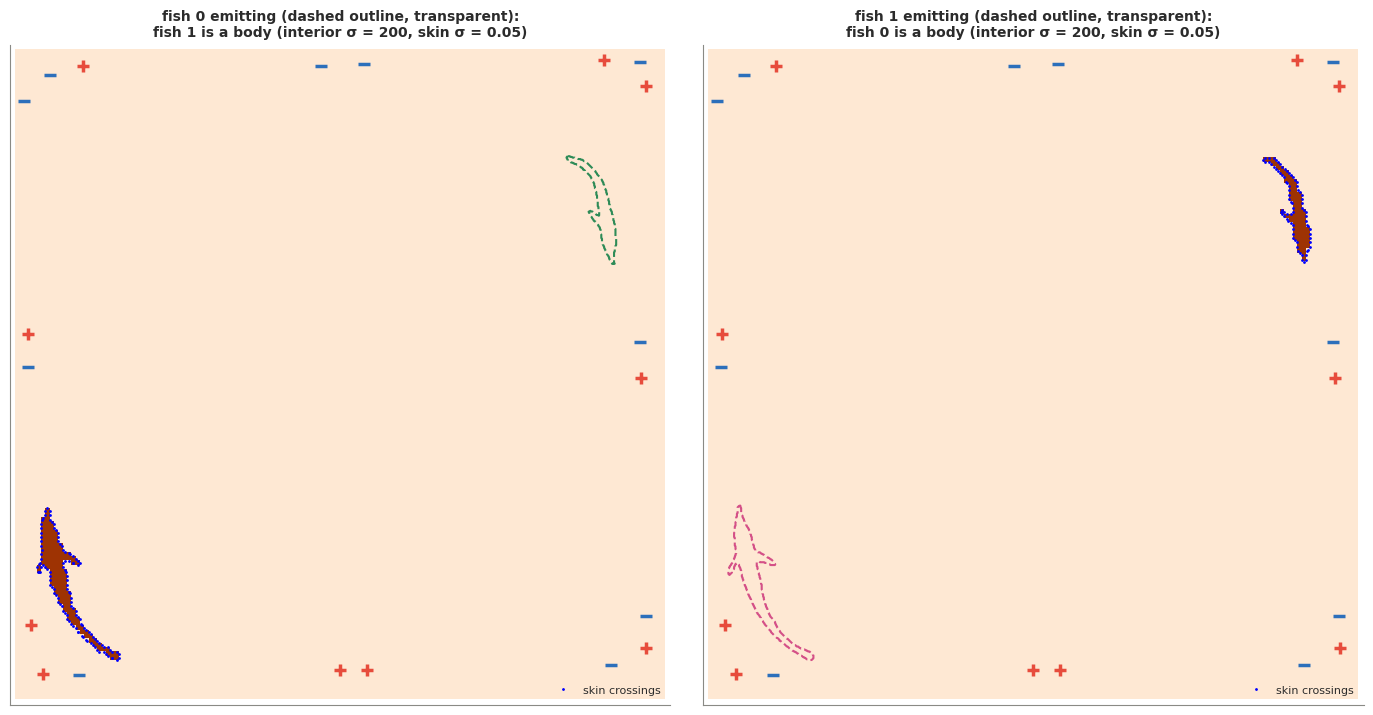

In [7]:
gw, gs, gi = gammas(OMEGA, **MAT)
print(f"sigma: water {gw.real}, skin {gs.real} (thickness {delta_h} cell = {delta_h * cell_px:.1f} px), interior {gi.real}")
occ = {f: occupancy_field(fm, N, skip=f) for f in FISH}

fig, ax = plt.subplots(1, 2, figsize=(14, 7))
for a, f in zip(ax, FISH):
    o = FISH[1 - f]
    gnode = np.where(occ[f] > 0.5, gi.real, gw.real)
    a.imshow(gnode, cmap='Oranges', norm=LogNorm(0.5, 400), extent=EXTENT)
    tx, ty = theta_outer(occ[f])
    ci, cj = np.nonzero(~np.isnan(tx)); a.plot(cj * cell_px, (ci + tx[ci, cj]) * cell_px, '.', color='b', ms=2)
    ci, cj = np.nonzero(~np.isnan(ty)); a.plot((cj + ty[ci, cj]) * cell_px, ci * cell_px, '.', color='b', ms=2, label='skin crossings')
    a.contour(fm[f], levels=[0.5], colors=[FISH_COLOR[f]], linewidths=1.5, linestyles='--')
    draw_electrodes(a, labels=False, ms=8)
    tank_axes(a, f'fish {f} emitting (dashed outline, transparent):\nfish {o} is a body (interior σ = {gi.real:g}, skin σ = {gs.real:g})')
    a.legend(fontsize=8, loc='lower right')
plt.tight_layout(); plt.show()

## 7. Potential and electric field

`build_A_shell` assembles the conductance matrix (5-point stencil, insulating walls: no edges leave the tank), and `solve_potential`
solves $A\varphi = -b$ with one node pinned, then removes the mean of φ. The electric field is $E = -\nabla\varphi$ (finite differences).

fish 0 emitting: phi from -0.545 to +0.210 | max |A phi + b| = 5.6e-15 (node 0 is pinned)


fish 1 emitting: phi from -0.692 to +0.232 | max |A phi + b| = 1.1e-14 (node 0 is pinned)


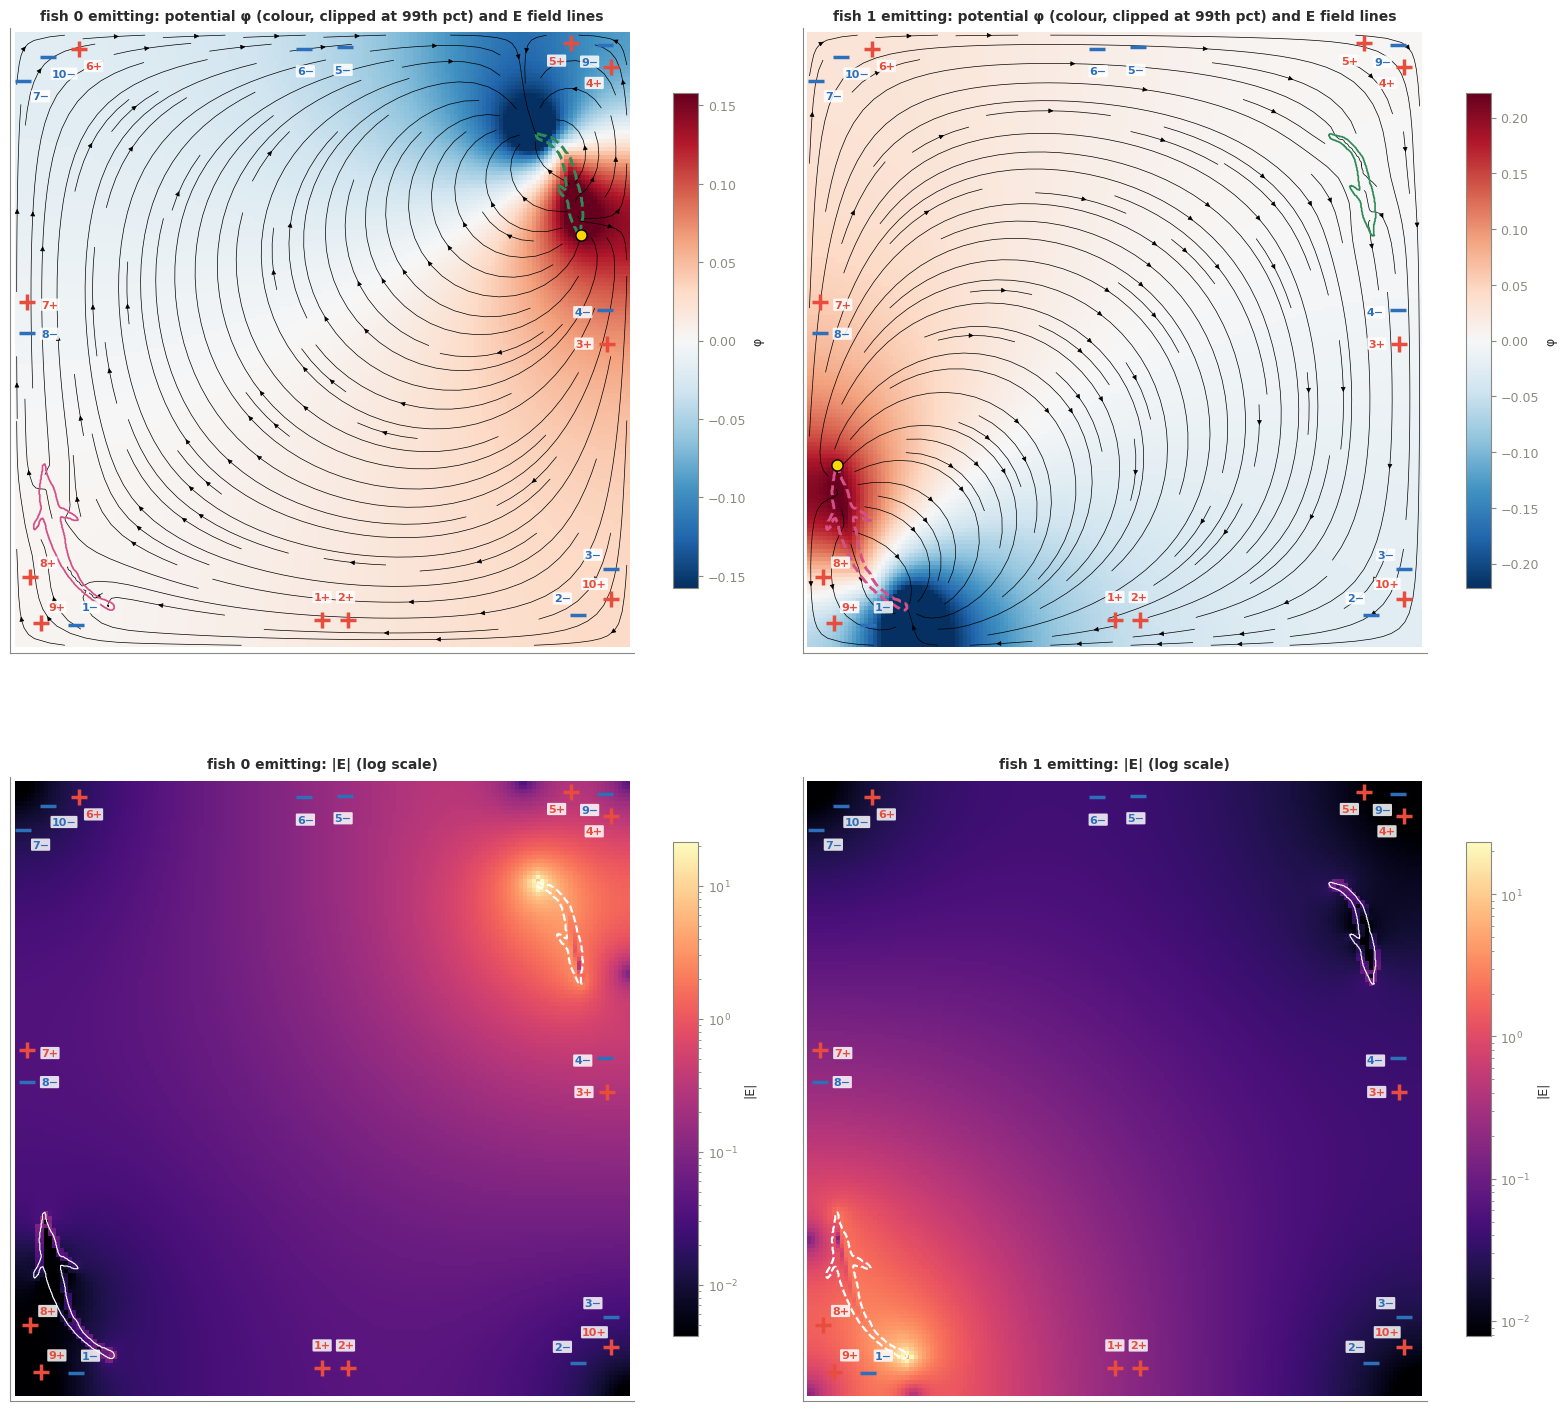

In [8]:
phi = {}
for f in FISH:
    A = build_A_shell(occ[f], N, delta_h, gw, gs, gi)
    phi[f] = unflatten_to_grid(solve_potential(A, b[f]), N).real
    resid = np.abs((A @ phi[f].ravel()).real + b[f].ravel())
    print(f"fish {f} emitting: phi from {phi[f].min():+.3f} to {phi[f].max():+.3f} | max |A phi + b| = {resid[1:].max():.1e} "
          f"(node 0 is pinned)")
    assert np.allclose(phi[f], candidate_field(fm, f, mids[f], N, delta_h, MAT, OMEGA).real)   # = eod_assign.candidate_field

gx = np.arange(N) * cell_px                                     # node pixel coordinates (row and column)
fig, ax = plt.subplots(2, 2, figsize=(16, 16))
for f in FISH:
    Er, Ec = (-d for d in np.gradient(phi[f], h))               # E along rows, along columns (tank units)
    Emag = np.hypot(Er, Ec)
    v = np.percentile(np.abs(phi[f]), 99)
    a = ax[0, f]
    im = a.imshow(phi[f], cmap='RdBu_r', vmin=-v, vmax=v, extent=EXTENT)
    a.streamplot(gx, gx, Ec, Er, color='k', density=1.3, linewidth=0.5, arrowsize=0.7)
    for l in FISH: a.contour(fm[l], levels=[0.5], colors=[FISH_COLOR[l]], linewidths=2 if l == f else 1.2,
                             linestyles='--' if l == f else '-')
    x, y = px(mids[f]); a.plot(x[-1], y[-1], 'o', color='gold', mec='k', ms=8)
    draw_electrodes(a); tank_axes(a, f'fish {f} emitting: potential φ (colour, clipped at 99th pct) and E field lines')
    plt.colorbar(im, ax=a, shrink=0.6, label='φ')
    a = ax[1, f]
    im = a.imshow(Emag, cmap='magma', norm=LogNorm(np.percentile(Emag, 1), Emag.max()), extent=EXTENT)
    for l in FISH: a.contour(fm[l], levels=[0.5], colors=['w'], linewidths=1.5 if l == f else 0.8, linestyles='--' if l == f else '-')
    draw_electrodes(a); tank_axes(a, f'fish {f} emitting: |E| (log scale)')
    plt.colorbar(im, ax=a, shrink=0.6, label='|E|')
plt.tight_layout(); plt.show()

## 8. Potential at the electrodes

`pair_voltages`: φ sampled at each electrode by bilinear interpolation between the 4 surrounding grid nodes (`sample_phi_point`), and
V(+) − V(−) per pair. This is the model pattern $v_f$ of each candidate emitter.

φ(+)            φ(−)         V(+) − V(−)        
emitter  fish 0  fish 1  fish 0  fish 1      fish 0  fish 1
pair                                                       
1        0.0147 -0.0564  0.0040 -0.1554      0.0107  0.0989
2        0.0164 -0.0488  0.0300 -0.0232     -0.0136 -0.0256
3        0.0688 -0.0080  0.0319 -0.0215      0.0369  0.0135
4       -0.0837  0.0023  0.0853 -0.0058     -0.1690  0.0081
5       -0.1051  0.0028 -0.0504  0.0120     -0.0547 -0.0092
6       -0.0188  0.0283 -0.0404  0.0147      0.0216  0.0136
7       -0.0073  0.0551 -0.0176  0.0298      0.0103  0.0253
8        0.0035  0.0489 -0.0055  0.0653      0.0090 -0.0164
9        0.0038 -0.0659 -0.0911  0.0024      0.0949 -0.0683
10       0.0309 -0.0224 -0.0181  0.0291      0.0490 -0.0515

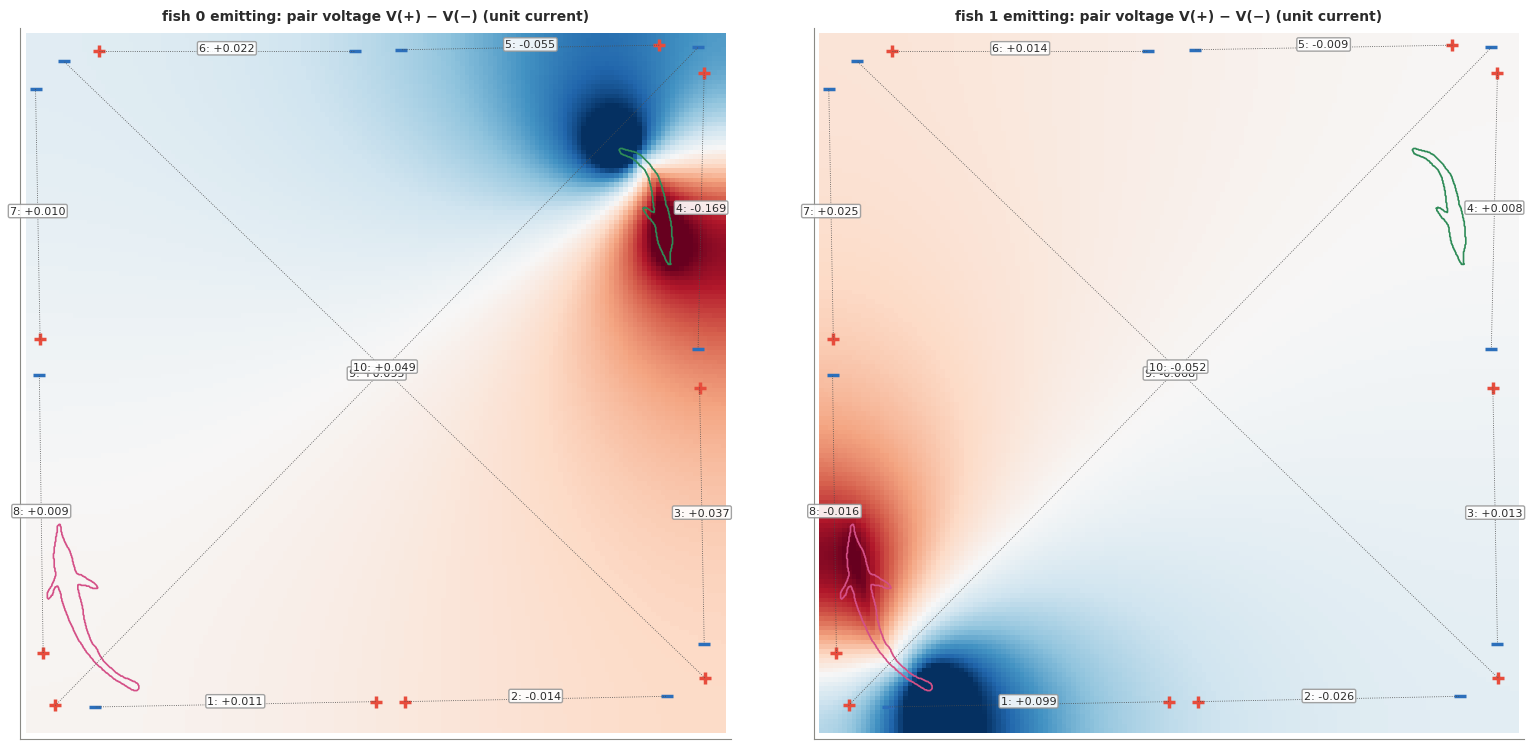

In [9]:
rows = []
for f in FISH:
    for pid, pp, pm in pairs:
        vp, vm = sample_phi_point(phi[f], pp, h, N), sample_phi_point(phi[f], pm, h, N)
        rows.append({'emitter': f'fish {f}', 'pair': pid, 'φ(+)': vp, 'φ(−)': vm, 'V(+) − V(−)': vp - vm})
tab = pd.DataFrame(rows)
v_model = {f: pair_voltages(phi[f], pairs, N) for f in FISH}
for f in FISH: assert np.allclose(v_model[f], tab[tab.emitter == f'fish {f}']['V(+) − V(−)'])
display(tab.pivot(index='pair', columns='emitter').round(4))

fig, ax = plt.subplots(1, 2, figsize=(16, 7.5))
for a, f in zip(ax, FISH):
    v = np.percentile(np.abs(phi[f]), 99)
    a.imshow(phi[f], cmap='RdBu_r', vmin=-v, vmax=v, extent=EXTENT)
    for l in FISH: a.contour(fm[l], levels=[0.5], colors=[FISH_COLOR[l]], linewidths=1.2)
    draw_electrodes(a, labels=False, ms=9)
    for pid, pp, pm in pairs:
        (xp, xm), (yp, ym) = px(np.stack([pp, pm])); a.plot([xp, xm], [yp, ym], color='0.3', lw=0.6, ls=':')
        a.text((xp + xm) / 2, (yp + ym) / 2, f'{pid}: {v_model[f][pair_ids.index(pid)]:+.3f}', fontsize=8, ha='center',
               bbox=dict(boxstyle='round,pad=0.15', fc='white', ec='0.6', alpha=0.9))
    tank_axes(a, f'fish {f} emitting: pair voltage V(+) − V(−) (unit current)')
plt.tight_layout(); plt.show()

## 9. Comparison and assignment

`compare_patterns(v_f, r)`: both vectors are scaled to max |v| = 1 (`normalize_peak`); the model's sign is flipped if that brings it
closer (the recorded sample may be in either phase of the EOD); the distance is the L2 norm of the difference. The fish with the smaller
distance gets the EOD. The last check compares with the voltages cached by the assignment run.

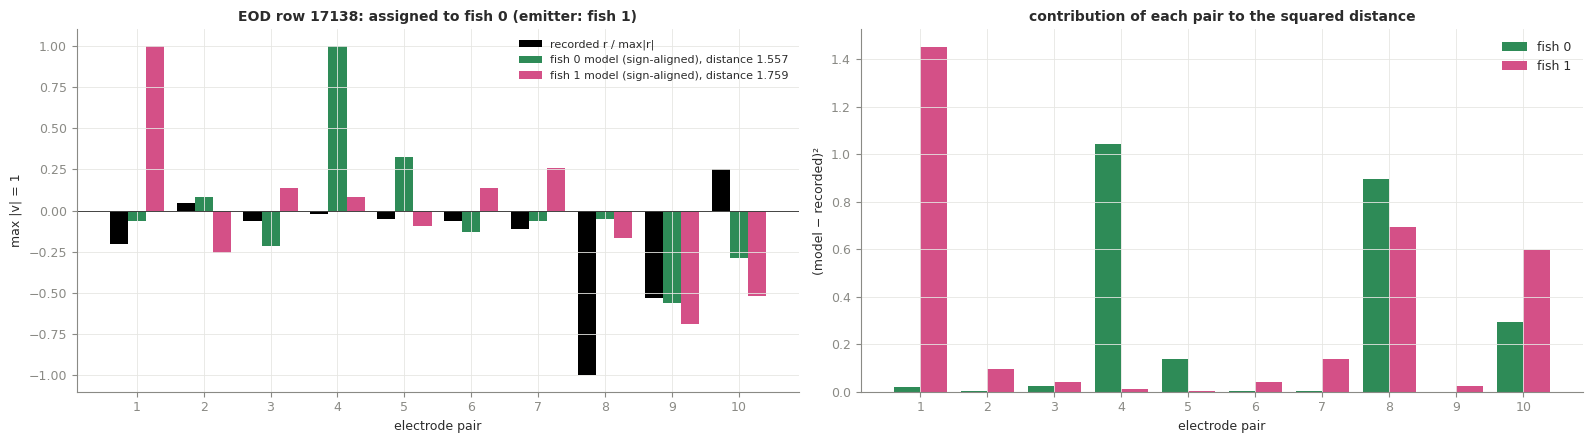

distances: fish 0 1.5574, fish 1 1.7591 -> fish 0 | same voltages as the assignment run: yes | assignment run gave fish 0


In [10]:
cmp = {f: compare_patterns(v_model[f], r) for f in FISH}
dist = {f: cmp[f][0] for f in FISH}
winner = min(dist, key=dist.get)

x, w = np.arange(len(pair_ids)), 0.27
fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
ax[0].bar(x - w, cmp[0][2], w, color='k', label='recorded r / max|r|')
for j, f in enumerate(FISH):
    ax[0].bar(x + j * w, cmp[f][1], w, color=FISH_COLOR[f], label=f'fish {f} model (sign-aligned), distance {dist[f]:.3f}')
ax[0].axhline(0, color='k', lw=0.5)
ax[0].set(xticks=x, xticklabels=pair_ids, xlabel='electrode pair', ylabel='max |v| = 1',
          title=f'EOD row {EOD_ROW}: assigned to fish {winner} (emitter: fish {EMITTER})'); ax[0].legend(fontsize=8)
for f in FISH:
    ax[1].bar(x + (f - 0.5) * 0.4, (cmp[f][1] - cmp[f][2]) ** 2, 0.4, color=FISH_COLOR[f], label=f'fish {f}')
ax[1].set(xticks=x, xticklabels=pair_ids, xlabel='electrode pair', ylabel='(model − recorded)²',
          title='contribution of each pair to the squared distance'); ax[1].legend()
plt.tight_layout(); plt.show()

cache = pd.read_pickle(f'{OUT}/model_voltages_N{N}.pkl').loc[EOD_ROW]
assert np.allclose(np.array([v_model[f] for f in FISH]), cache.u) and np.allclose(r, cache.v_rec)
saved = pd.read_csv(f'{OUT}/eod_assignments_my_pipeline.csv', index_col='row').loc[EOD_ROW, 'fish | shape only']
print(f"distances: " + ', '.join(f'fish {f} {dist[f]:.4f}' for f in FISH) + f" -> fish {winner} | "
      f"same voltages as the assignment run: yes | assignment run gave fish {saved}")

## 10. Recorded voltage vs my model vs Denis' model, per electrode pair

One panel per electrode pair, one row per candidate fish, three traces each, every one scaled to max |v| = 1 (per fish):
- **recorded** (black): the 25-sample window divided by its |value| at the peak sample;
- **my model** (colour): the pair voltages of section 8 for that fish, divided by their max |v|, with the sign chosen in section 9;
- **Denis' model** (grey dashed): his `normalized_predicted_PTP` for that fish (`Assigned_Data_1fish_*.pkl`). He compares
  peak-to-peak values with a signed cosine similarity, so his sign is kept and turned into the peak-sample convention with the sign
  relating his `recorded_PTP` to the recording at the peak sample. His fish A/B is matched to a mask by where his mouth, head and
  middle keypoints (score > 0.5) lie.

Both models predict one number per pair; it is drawn as that number times the recording's own EOD waveform (rank-1 fit of the 10
traces, 1 at the peak sample). Row labels: my L2 distance (smaller = better) and Denis' cosine similarity (larger = better).

Denis' fish -> mask: {1: 'A', 0: 'B'} | Denis assigned fish 0 (B) | my pipeline: fish 0


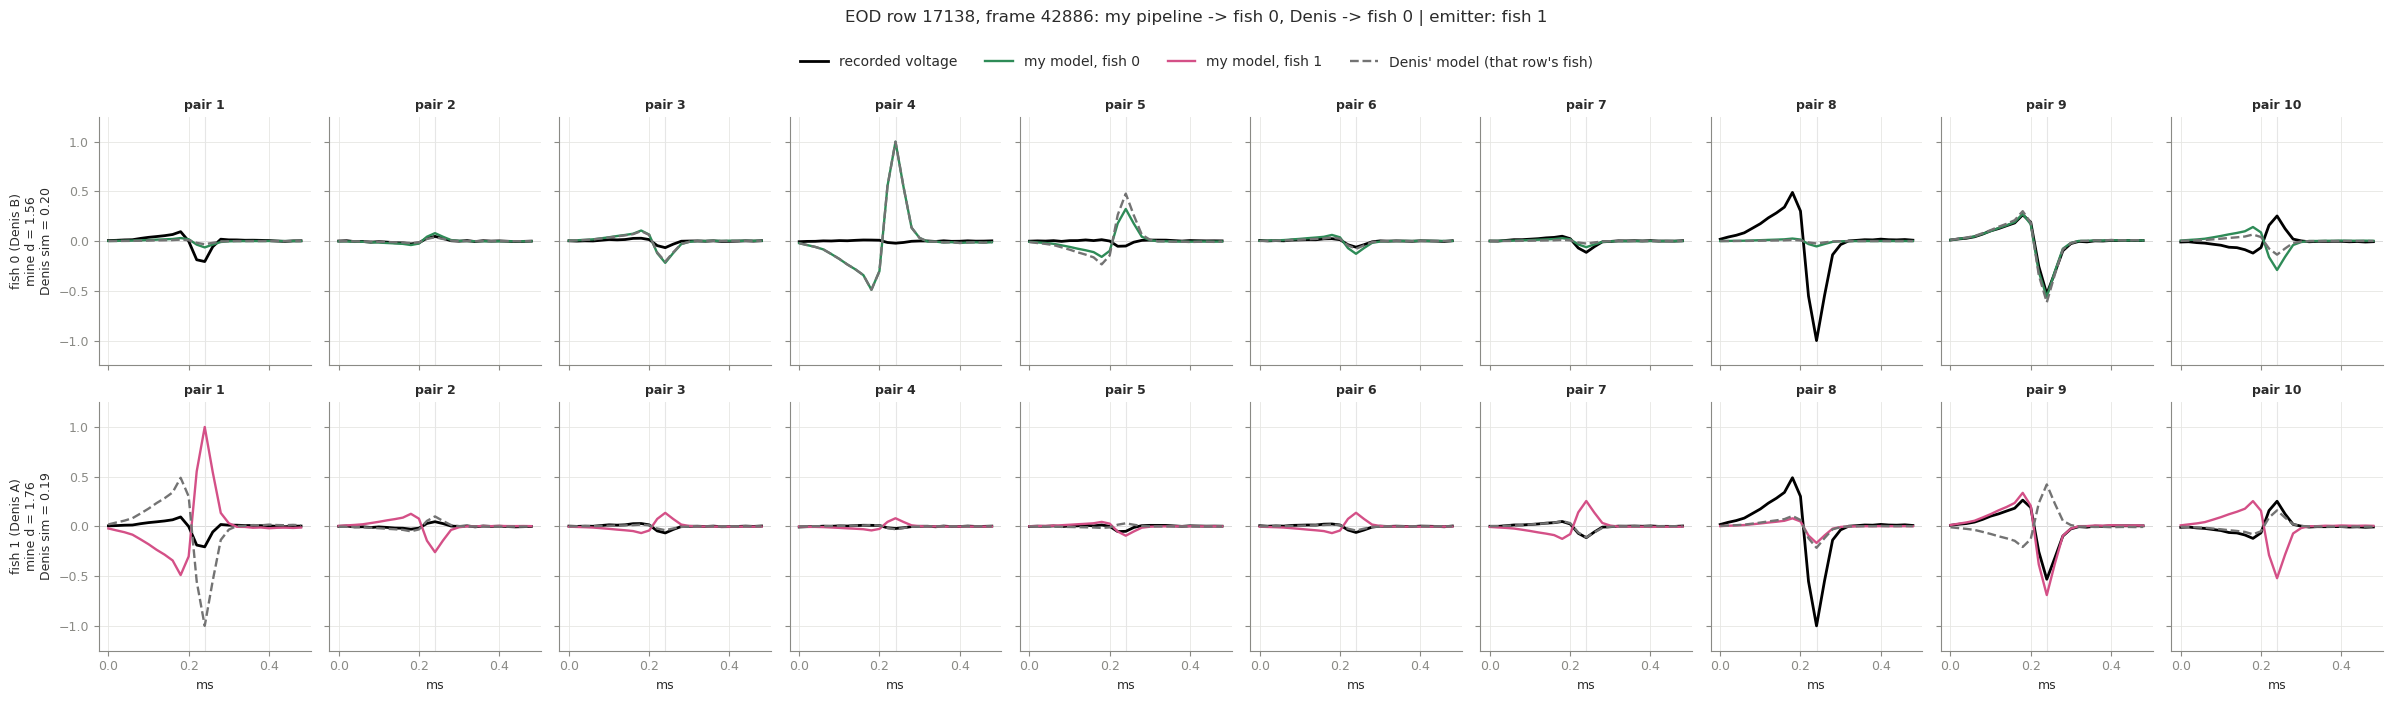

In [11]:
from matplotlib.lines import Line2D
from eod_assign import rank1_pattern

DENIS_PKL = 'results/eod_assignment_2_fish_silent/Assigned_Data_1fish_2024-02-13T14_33_21.pkl'
PX_PER_CM = 912 / 60                                              # Denis' pixel2cm calibration
den = pd.read_pickle(DENIS_PKL)
assert len(den) == len(df_eod) and (den.Frame.to_numpy() == df_eod.Frame.to_numpy()).all()
dp = den.loc[EOD_ROW]

def denis_mask(X):
    '''Mask label holding most of Denis' confident mouth, head and middle keypoints of his fish X.'''
    votes = []
    for kp in ('mouth', 'head', 'middle'):
        if not dp[f'score_{kp}_{X}'] > 0.5: continue
        x, y = np.round(np.asarray(dp[f'{kp}_{X}']) * PX_PER_CM).astype(int)
        votes += [f for f in FISH if 0 <= y < P and 0 <= x < P and fm[f][y, x]]
    return max(set(votes), key=votes.count)

letter = {denis_mask(X): X for X in 'AB'}
assert sorted(letter) == list(FISH), letter
w = rank1_pattern(V)[1]; w = w / w[t_star]                       # EOD waveform, 1 at the peak sample
sigma = np.sign(np.asarray(dp.recorded_PTP) @ r)                  # Denis' PTP sign -> peak-sample sign
denis_fish = {X: f for f, X in letter.items()}[dp.discharging_fish]
print(f"Denis' fish -> mask: {letter} | Denis assigned fish {denis_fish} ({dp.discharging_fish}) | my pipeline: fish {winner}")

fig, ax = plt.subplots(2, len(pair_ids), figsize=(24, 6.5), sharex=True, sharey=True)
for f in FISH:
    X = letter[f]
    mine = cmp[f][1]                                              # normalized, sign-aligned (section 9)
    denis = sigma * np.asarray(dp[f'normalized_predicted_PTP_{X}'])
    for k, pid in enumerate(pair_ids):
        a = ax[f, k]
        a.axhline(0, color='0.85', lw=0.6); a.axvline(t_ms[t_star], color='0.9', lw=0.8)
        a.plot(t_ms, V[k] / np.abs(r).max(), color='k', lw=2)
        a.plot(t_ms, mine[k] * w, color=FISH_COLOR[f], lw=1.7)
        a.plot(t_ms, denis[k] * w, color='0.45', lw=1.7, ls='--')
        a.set_title(f'pair {pid}', fontsize=9); a.set_ylim(-1.25, 1.25)
    ax[f, 0].set_ylabel(f"fish {f} (Denis {X})\nmine d = {dist[f]:.2f}\nDenis sim = {dp[f'similarity_{X}']:.2f}", fontsize=9)
for a in ax[1]: a.set_xlabel('ms')
fig.legend(handles=[Line2D([], [], color='k', lw=2, label='recorded voltage'),
                    Line2D([], [], color=FISH_COLOR[0], lw=1.7, label='my model, fish 0'),
                    Line2D([], [], color=FISH_COLOR[1], lw=1.7, label='my model, fish 1'),
                    Line2D([], [], color='0.45', lw=1.7, ls='--', label="Denis' model (that row's fish)")],
           loc='upper center', bbox_to_anchor=(0.5, 1.02), ncol=4, fontsize=10, frameon=False)
fig.suptitle(f"EOD row {EOD_ROW}, frame {FRAME}: my pipeline -> fish {winner}, Denis -> fish {denis_fish} | emitter: fish {EMITTER}",
             y=1.07, fontsize=12)
plt.tight_layout(); plt.show()

## 11. Moving the sink away from the tail tip

So far the sink (−1) sits on the very first midline point, the tail tip. Here it is moved forward along the midline by a fraction
`frac` of the body length; the +1 is spread equally over the midline points between the sink and the head, and the points behind the
sink (towards the tail tip) carry no current. `frac = 0` is the model used so far (`multipole_sources`). Everything else is unchanged
(same grid, bodies and conductivities, same comparison), and both candidate fish get the same source layout.

In [12]:
SINK_FRACS = (0.0, 0.1, 0.2, 0.3)                                 # sink position, fraction of body length from the tail tip

def shifted_sources(midline, frac):
    '''Point currents along a midline (tail -> head): sink -1 at the point `frac` of the body length from the tail tip, +1/m at each
       of the m points between it and the head, 0 behind it. frac = 0 gives multipole_sources(midline, I0=1).'''
    pos = np.asarray(midline, float); n = len(pos) - 1
    k = int(round(frac * n))
    cur = np.zeros(n + 1); cur[k] = -1.0; cur[k + 1:] = 1.0 / (n - k)
    return pos, cur

for f in FISH: assert np.allclose(shifted_sources(mids[f], 0)[1], multipole_sources(mids[f], I0=1.0)[1])

A_f = {f: build_A_shell(occ[f], N, delta_h, gw, gs, gi) for f in FISH}         # conductances do not depend on the sources
phi_s, v_s, d_s = {}, {}, {}
for s in SINK_FRACS:
    for f in FISH:
        pos, cur = shifted_sources(mids[f], s)
        phi_s[s, f] = unflatten_to_grid(solve_potential(A_f[f], build_multipole_b(pos, cur, h, N)), N).real
        v_s[s, f] = pair_voltages(phi_s[s, f], pairs, N)
        d_s[s, f] = compare_patterns(v_s[s, f], r)[0]
assert all(np.allclose(v_s[0.0, f], v_model[f]) for f in FISH)                  # frac = 0 reproduces section 8

L_px = {f: np.linalg.norm(np.diff(mids[f], axis=0), axis=1).sum() * (P - 1) for f in FISH}
scan = pd.DataFrame([{'sink at (fraction of body length)': s, **{f'sink distance from tail tip, fish {f} (px)': s * L_px[f] for f in FISH},
                      **{f'distance fish {f}': d_s[s, f] for f in FISH},
                      'assigned': min(FISH, key=lambda f: d_s[s, f])} for s in SINK_FRACS]).set_index('sink at (fraction of body length)')
display(scan.round(3))

,"sink distance from tail tip, fish 0 (px)","sink distance from tail tip, fish 1 (px)",distance fish 0,distance fish 1,assigned
sink at (fraction of body length),,,,,
0.0,0.000,0.000,1.557,1.759,0
0.1,17.511,25.223,1.566,1.503,1
0.2,35.021,50.446,1.571,1.437,1
0.3,52.532,75.669,1.571,1.282,1


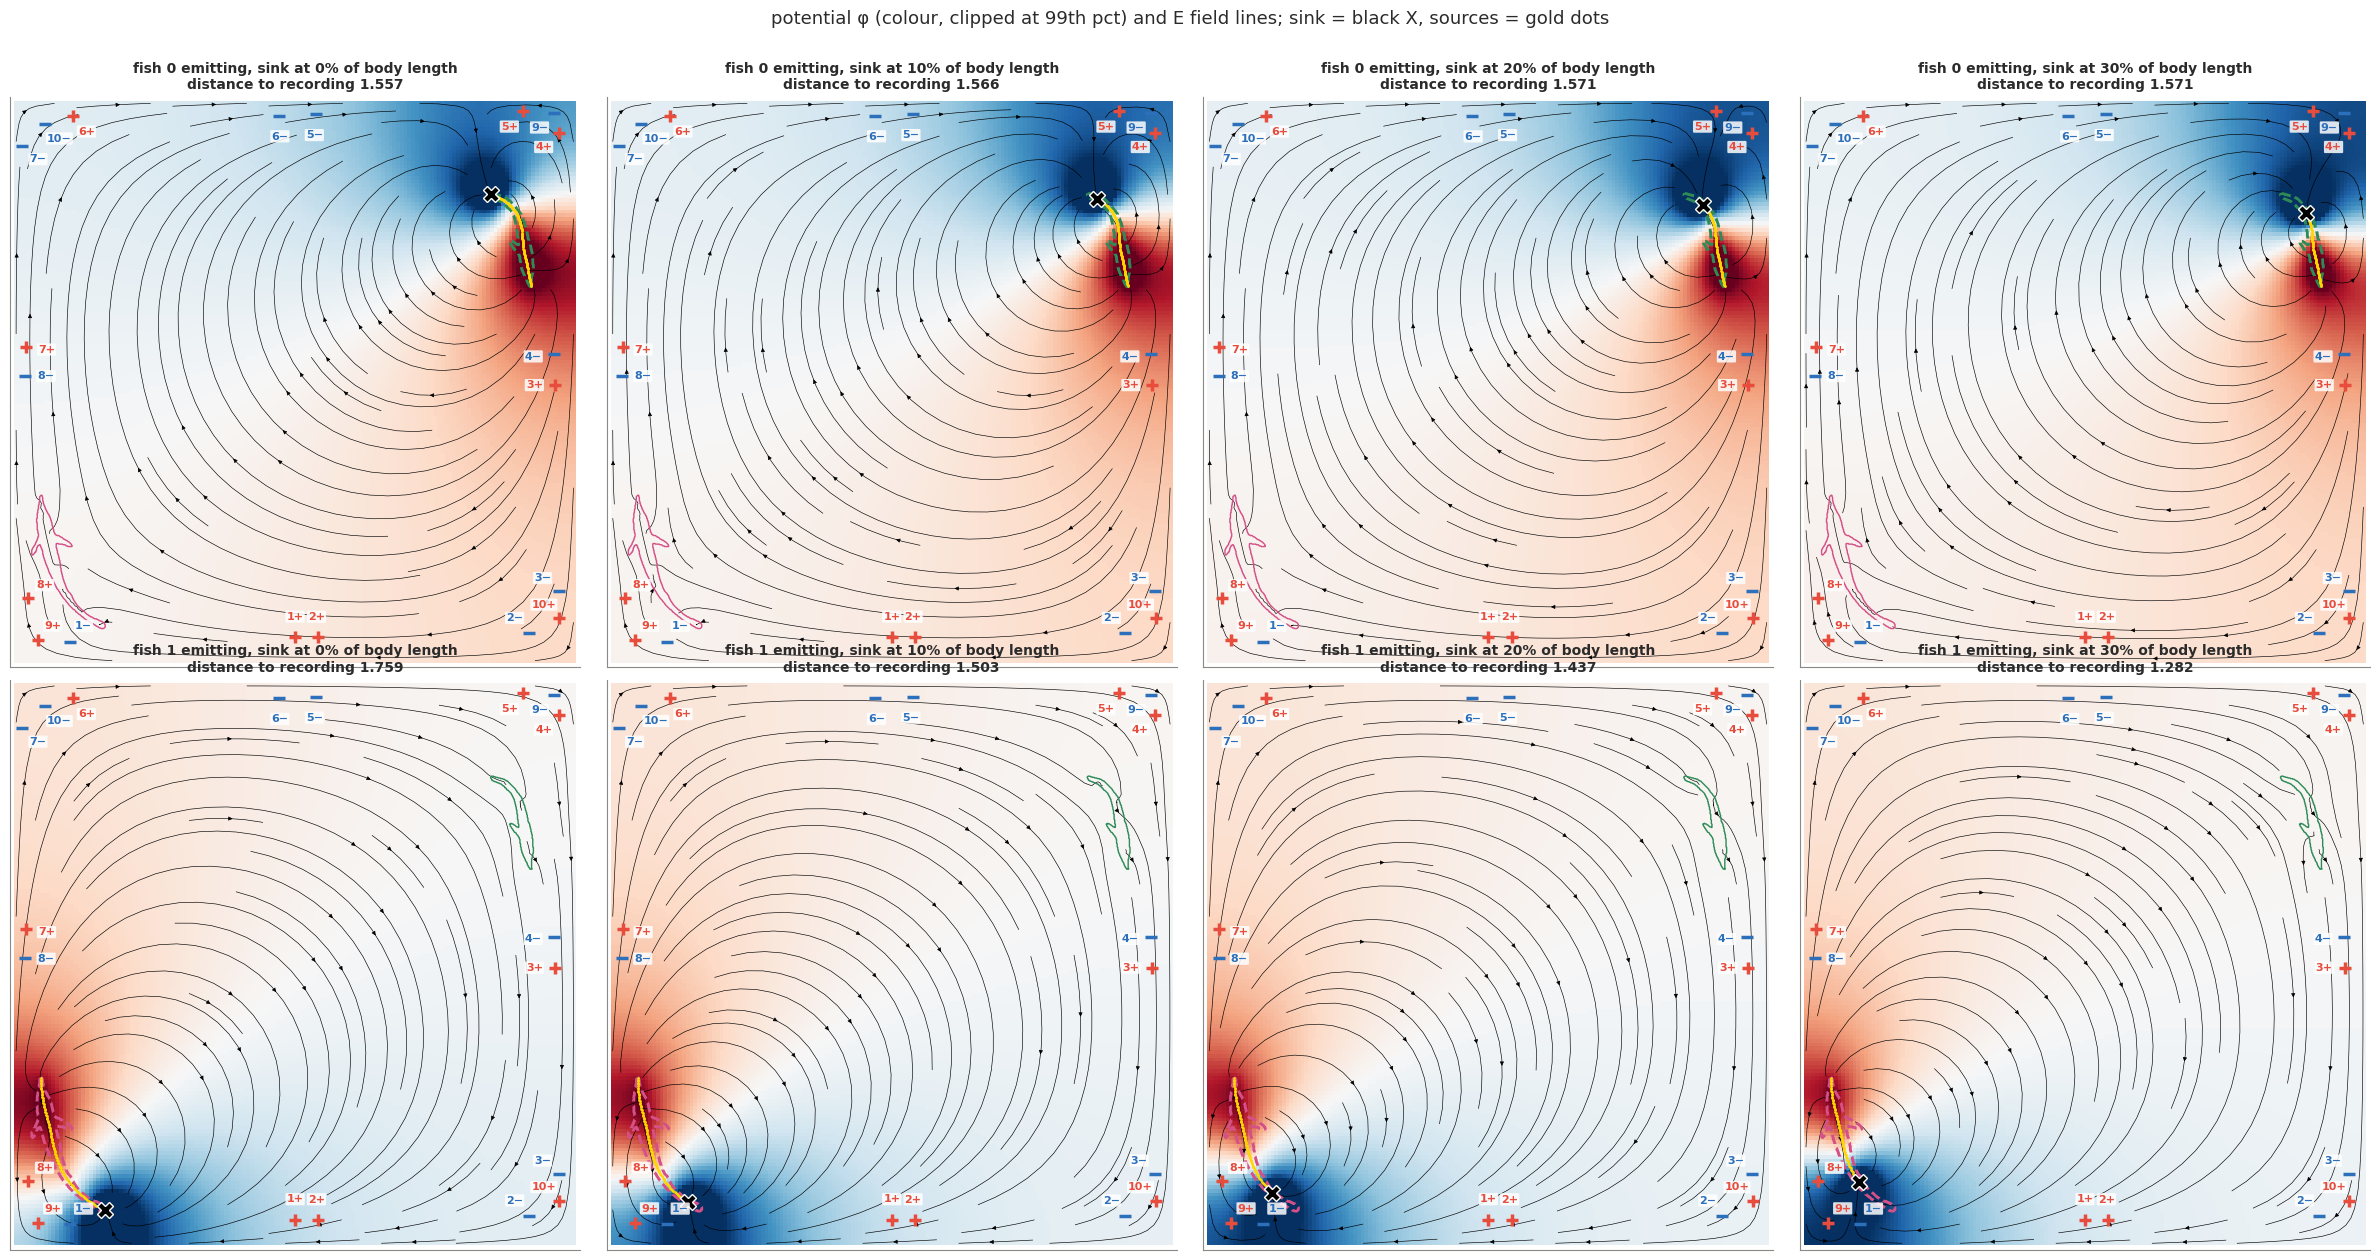

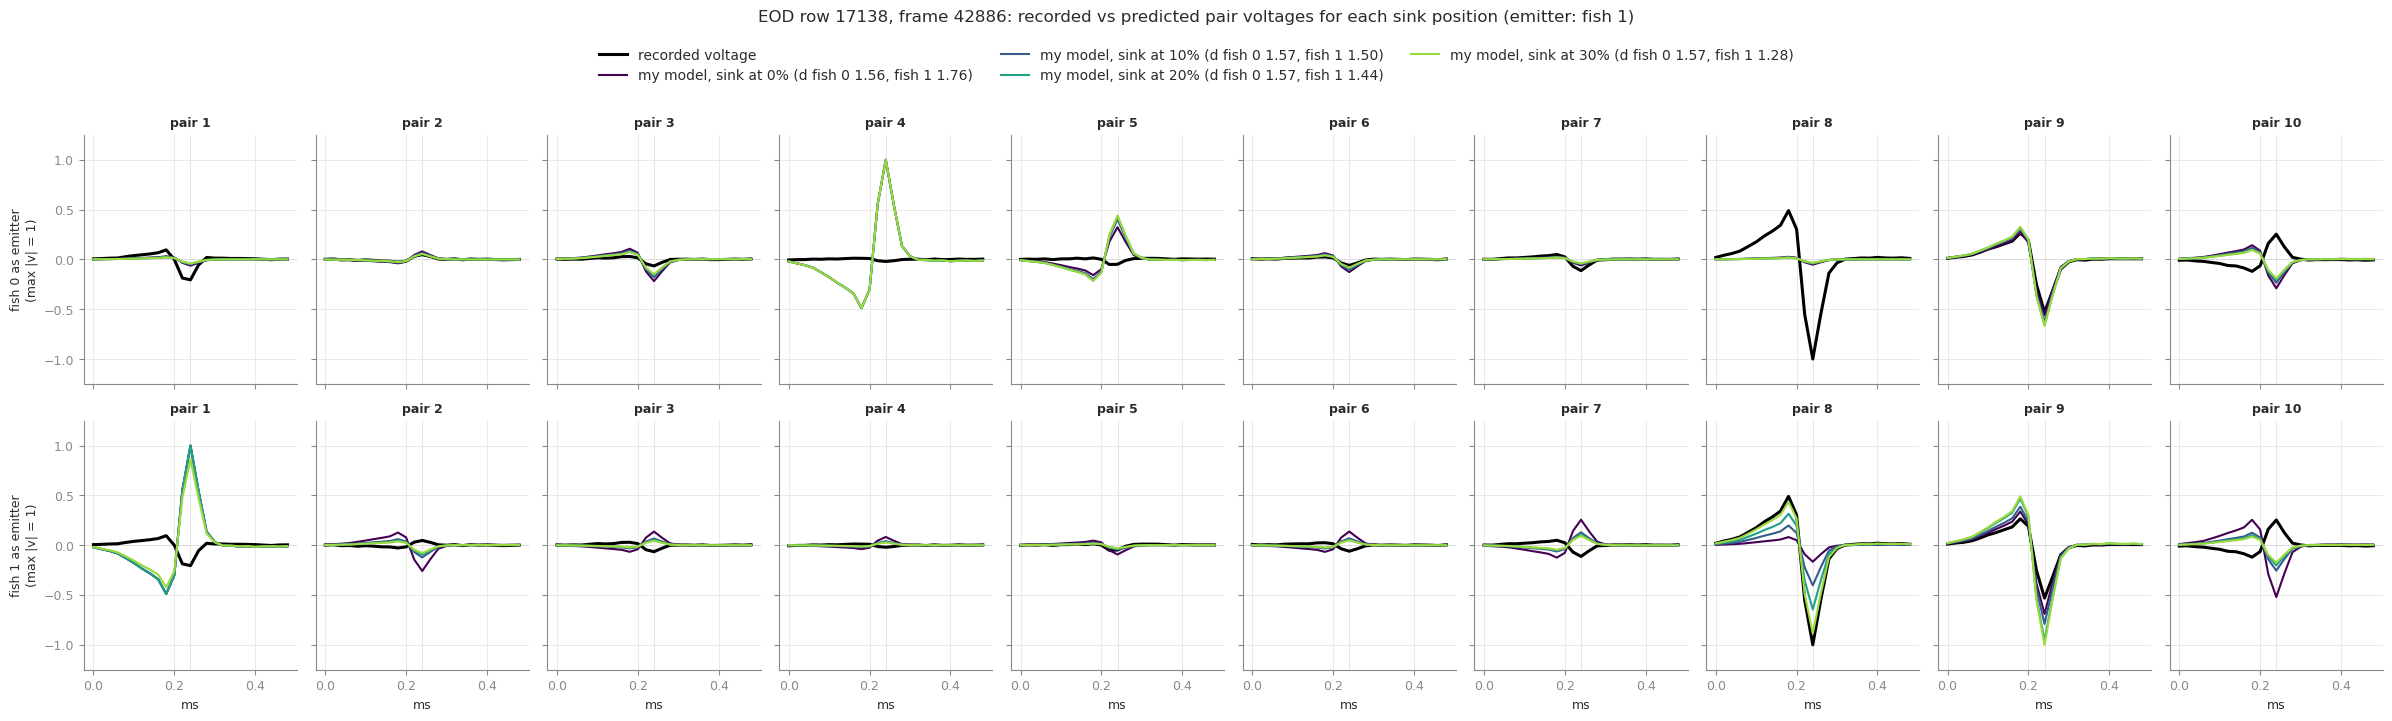

In [13]:
fig, ax = plt.subplots(len(FISH), len(SINK_FRACS), figsize=(6 * len(SINK_FRACS), 6.3 * len(FISH)))
for f in FISH:
    for j, s in enumerate(SINK_FRACS):
        a = ax[f, j]; p = phi_s[s, f]
        Er, Ec = (-d for d in np.gradient(p, h))
        v = np.percentile(np.abs(p), 99)
        a.imshow(p, cmap='RdBu_r', vmin=-v, vmax=v, extent=EXTENT)
        a.streamplot(gx, gx, Ec, Er, color='k', density=1.0, linewidth=0.45, arrowsize=0.6)
        for l in FISH: a.contour(fm[l], levels=[0.5], colors=[FISH_COLOR[l]], linewidths=2 if l == f else 1,
                                 linestyles='--' if l == f else '-')
        pos, cur = shifted_sources(mids[f], s)
        x, y = px(pos); k = int(np.argmin(cur))
        a.plot(x[k + 1:], y[k + 1:], '.', color='gold', ms=2); a.plot(x[k], y[k], 'X', color='k', mec='w', ms=11)
        draw_electrodes(a, ms=8)
        tank_axes(a, f'fish {f} emitting, sink at {s:.0%} of body length\n'
                     f'distance to recording {d_s[s, f]:.3f}')
fig.suptitle('potential φ (colour, clipped at 99th pct) and E field lines; sink = black X, sources = gold dots', fontsize=13, y=0.995)
plt.tight_layout(rect=(0, 0, 1, 0.975)); plt.show()

shade = plt.cm.viridis(np.linspace(0, 0.85, len(SINK_FRACS)))
fig, ax = plt.subplots(len(FISH), len(pair_ids), figsize=(24, 6.5), sharex=True, sharey=True)
for f in FISH:
    for k, pid in enumerate(pair_ids):
        a = ax[f, k]
        a.axhline(0, color='0.85', lw=0.6); a.axvline(t_ms[t_star], color='0.9', lw=0.8)
        a.plot(t_ms, V[k] / np.abs(r).max(), color='k', lw=2.2)
        for s, c in zip(SINK_FRACS, shade):
            a.plot(t_ms, compare_patterns(v_s[s, f], r)[1][k] * w, color=c, lw=1.5)
        a.set_title(f'pair {pid}', fontsize=9); a.set_ylim(-1.25, 1.25)
    ax[f, 0].set_ylabel(f'fish {f} as emitter\n(max |v| = 1)', fontsize=9)
for a in ax[1]: a.set_xlabel('ms')
fig.legend(handles=[Line2D([], [], color='k', lw=2.2, label='recorded voltage')] +
                   [Line2D([], [], color=c, lw=1.5, label=f'my model, sink at {s:.0%} (d fish 0 {d_s[s, 0]:.2f}, fish 1 {d_s[s, 1]:.2f})')
                    for s, c in zip(SINK_FRACS, shade)],
           loc='upper center', bbox_to_anchor=(0.5, 1.06), ncol=3, fontsize=10, frameon=False)
fig.suptitle(f'EOD row {EOD_ROW}, frame {FRAME}: recorded vs predicted pair voltages for each sink position (emitter: fish {EMITTER})',
             y=1.1, fontsize=12)
plt.tight_layout(); plt.show()